# 24 Their bursts measured again: E_peak of the main emission and of the precursor, and the lags

E_p,ME is the one spectral number in Zhu et al.'s classification, and it enters EPI squared, so a 10% error in it moves EPI by 0.08. This notebook fits the precursor and main emission of every burst from notebook 23 two ways on the same spectra, compares E_p,ME with their table, and adds what their papers don't have: the precursor's own E_peak, with errors or limits. Then the lags.

1. Two ways of fitting
2. The two bursts whose fits they printed, model by model
3. E_p,ME their way, against their table
4. Their way against our rule
5. The precursor's E_peak
6. The lags
7. What this says

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from zhu import RESULTS
from zhu.catalogue import SPECTRA_2025, read_table_2026
from zhu.features import collect

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
FIGURES = Path("figures")
COLOURS = {"I-S": "#2a78d6", "I-L": "#eb6834", "II": "0.6"}

table = read_table_2026()
ours = collect("zhu2026")
ours["Type"] = table.loc[ours.index, "Type"]
spectra = {name: pd.read_csv(RESULTS / name / "spectra_zhu2026.csv", index_col=0) for name in ours.index if (RESULTS / name / "spectra_zhu2026.csv").exists()}
print(len(spectra), "bursts with spectra")
failed = {name: s.filter(like="failed").dropna(axis=1, how="all").to_dict("index") for name, s in spectra.items() if s.filter(like="failed").notna().any().any()}
print("fits that failed:", failed or "none")

110 bursts with spectra
fits that failed: none


## 1. Two ways of fitting

`zhu/spectra.py` builds the source and background spectra of each window once (the same as every notebook since 08: the background polynomial of each detector integrated over the window, the response for the window's time) and fits them two ways in the same worker.

| | Their way (Zhu et al. 2025 section 2.3, 2026 section 2.2) | Our rule (grbtool, notebook 14) |
|---|---|---|
| NaI | 10-900 keV, without 30-40 keV (iodine K edge) | 8-900 keV |
| BGO | 0.3-40 MeV; 0.3-10 MeV for a precursor | 0.2-40 MeV |
| statistic | PGSTAT | PSTAT |
| models | Band, CPL, Band+BB, CPL+BB, PL+BB | Comptonized, Band, two-break Band; PL and BB as checks |
| choice | lowest BIC = -2 ln L + k ln N among models with all parameters constrained | two-break if a clean break beats Band by Delta C > 11.8, Band if the tail is needed by Delta C > 9, else Comptonized |
| E_p error | MCMC in XSPEC | profile likelihood |

"Constrained" is read as: finite errors from the covariance, every parameter away from its limits, and amplitudes, E_peak and kT known to better than 100%. They don't define it. A window is only quoted as measured by our rule if it is at least 5 sigma and the Comptonized model beats a power law by Delta C > 9; otherwise the 95% interval of the Comptonized E_peak is given.

## 2. The two bursts whose fits they printed, model by model

Their 2025 paper prints all five model fits for the precursor and main emission of GRB 090131 and 090618 (their windows). Our fits use our windows, which for these two are the same within a bin or two at the start and within a few seconds for 090618's precursor (notebook 23).

In [2]:
rows = []
for (name, label), theirs in SPECTRA_2025.items():
    if name not in spectra or label not in spectra[name].index:
        continue
    r = spectra[name].loc[label]
    for model, (ep, lo, hi, bic) in theirs.items():
        rows.append(dict(GRB=name, episode=label, model=model, their_Ep=ep, their_err=(None if ep is None else f"-{lo:g}/+{hi:g}"), their_BIC=bic,
                         our_Ep=r.get(f"zhu_{model}_Epeak", np.nan), our_BIC=r.get(f"zhu_{model}_bic", np.nan), constrained=r.get(f"zhu_{model}_constrained", np.nan)))
printed = pd.DataFrame(rows)
for (name, label), group in printed.groupby(["GRB", "episode"]):
    group = group.copy()
    group["their_dBIC"] = group.their_BIC - group.their_BIC.min()
    group["our_dBIC"] = group.our_BIC - group.our_BIC.min()
    print(f"{name} {label}: our choice {spectra[name].loc[label, 'zhu_model']}, E_p {spectra[name].loc[label, 'zhu_Epeak']:.1f}")
    print(group[["model", "their_Ep", "their_err", "our_Ep", "their_dBIC", "our_dBIC", "constrained"]].round(1).to_string(index=False))

090131A ME: our choice band_bb, E_p 65.0
  model  their_Ep     their_err  our_Ep  their_dBIC  our_dBIC  constrained
   band      48.7 -10.32/+10.15    45.1         7.7       9.3         True
    cpl      53.9   -5.65/+5.63    53.8         6.7      23.1         True
band_bb      62.0 -15.25/+15.64    65.0         1.0       0.0         True
 cpl_bb      68.2 -15.79/+16.26    69.5         0.0       4.1         True
090131A PE: our choice cpl, E_p 1824.8
  model  their_Ep         their_err  our_Ep  their_dBIC  our_dBIC  constrained
   band    1707.2  -950.91/+1073.06  1823.3         2.5       5.7        False
    cpl    1769.4 -1030.29/+1041.45  1824.8         0.2       0.0        False
band_bb    1855.7 -1492.06/+1259.22  1823.3         8.7      15.0        False
 cpl_bb    1031.2   -641.54/+641.19  1824.8         5.8       9.3        False
  pl_bb       NaN               NaN     NaN         0.0       7.4        False
090618A ME: our choice band, E_p 184.3
  model  their_Ep     their_err 

On nearly the same windows, our fits give nearly their E_peak model by model. GRB 090131's main emission: 45, 54, 65 and 70 keV against
their 49, 54, 62 and 68 keV for Band, Comptonized, Band+BB and Comptonized+BB; GRB 090618's: 184 against 173 keV (Band) and its
precursor 169 against 161 keV. Which model wins can differ when two are close: for 090131's main emission their BIC prefers
Comptonized+BB by 1.0 over Band+BB, and on our window Band+BB wins by 4.1. GRB 090131's precursor is unconstrained either way (E_peak
near 1.8 MeV with errors as large as the value).

## 3. E_p,ME their way, against their table

In [3]:
me = ours[["Type", "Ep_ME_zhu", "Ep_ME_zhu_lo", "Ep_ME_zhu_hi", "model_ME_zhu", "Ep_ME_ours", "Ep_ME_ours_lo", "Ep_ME_ours_hi", "model_ME_ours", "measured_ME"]].copy()
me["theirs"] = table.loc[me.index, "Ep_ME"]
me["dex"] = np.log10(me.Ep_ME_zhu / me.theirs)
me["err_dex"] = np.log10(1 + np.where(me.dex > 0, me.Ep_ME_zhu_lo, me.Ep_ME_zhu_hi) / me.Ep_ME_zhu)
me["pull"] = me.dex / me.err_dex
d = me.dex.dropna()
print(len(d), "bursts; median", round(d.median(), 3), "dex; within 0.05 dex", round(np.mean(np.abs(d) < 0.05), 2), "; within 0.1 dex", round(np.mean(np.abs(d) < 0.1), 2),
      "; beyond 0.3 dex", int(np.sum(np.abs(d) > 0.3)))
print("their value inside our 68% interval for", round(np.mean(np.abs(me.pull.dropna()) <= 1), 2), "of them")
print("models chosen their way:", me.model_ME_zhu.value_counts().to_dict())
print(me[np.abs(me.dex) > 0.3][["Type", "theirs", "Ep_ME_zhu", "model_ME_zhu", "Ep_ME_ours", "model_ME_ours"]].round(1).to_string())

109 bursts; median -0.02 dex; within 0.05 dex 0.45 ; within 0.1 dex 0.67 ; beyond 0.3 dex 11
their value inside our 68% interval for 0.46 of them
models chosen their way: {'cpl': 79, 'band': 20, 'band_bb': 5, 'cpl_bb': 4, 'pl_bb': 2}
        Type  theirs  Ep_ME_zhu model_ME_zhu  Ep_ME_ours model_ME_ours
name                                                                  
131216A   II   689.8      258.1          cpl       346.8   Comptonized
131217B   II   643.8      320.8          cpl       351.7   Comptonized
140329A   II   491.8      205.9         band       279.8  BandLowBreak
150804A   II   333.3      160.6          cpl       162.9   Comptonized
160509A   II  1083.4      349.4         band       601.6  BandLowBreak
170310A   II    96.0     6538.6          cpl      9056.8   Comptonized
170802A  I-S  1469.4      708.8         band       884.6   Comptonized
170923B   II  1002.2     4466.2          cpl      4346.9   Comptonized
190829A   II    39.3        7.8        pl_bb        10.8

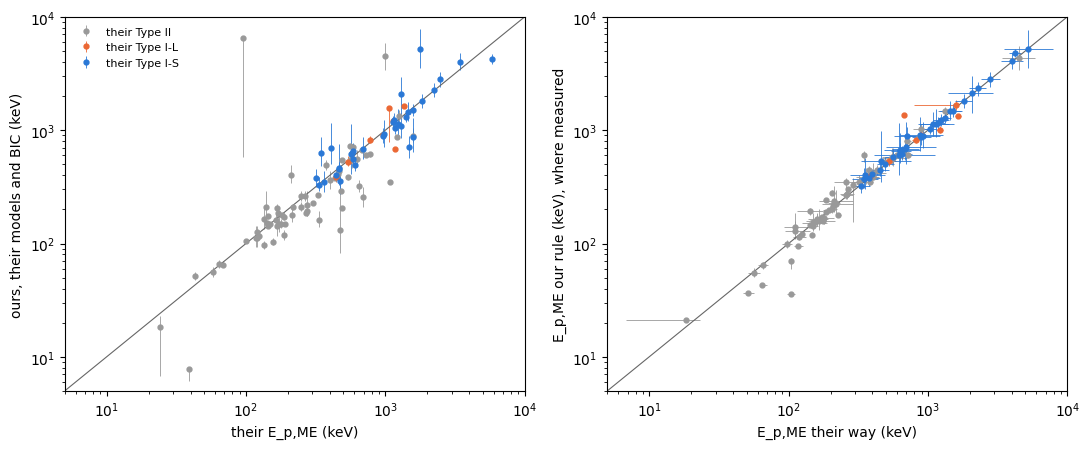

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axes[0]
for kind in ("II", "I-L", "I-S"):
    sel = me[(me.Type == kind) & me.Ep_ME_zhu.notna()]
    ax.errorbar(sel.theirs, sel.Ep_ME_zhu, yerr=[sel.Ep_ME_zhu_lo.fillna(0), sel.Ep_ME_zhu_hi.fillna(0)], fmt="o", ms=3.5, color=COLOURS[kind], elinewidth=0.6, label=f"their Type {kind}")
lim = [5, 1e4]
ax.plot(lim, lim, color="0.4", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("their E_p,ME (keV)"); ax.set_ylabel("ours, their models and BIC (keV)")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
both = me[me.measured_ME.astype(str) == "True"].dropna(subset=["Ep_ME_zhu", "Ep_ME_ours"])
for kind in ("II", "I-L", "I-S"):
    sel = both[both.Type == kind]
    ax.errorbar(sel.Ep_ME_zhu, sel.Ep_ME_ours, xerr=[sel.Ep_ME_zhu_lo.fillna(0), sel.Ep_ME_zhu_hi.fillna(0)], yerr=[sel.Ep_ME_ours_lo.fillna(0), sel.Ep_ME_ours_hi.fillna(0)],
                fmt="o", ms=3.5, color=COLOURS[kind], elinewidth=0.6)
ax.plot(lim, lim, color="0.4", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("E_p,ME their way (keV)"); ax.set_ylabel("E_p,ME our rule (keV), where measured")
fig.tight_layout()
fig.savefig(FIGURES / "24_epeak_main.png", dpi=140)
plt.show()

Fitted their way, our E_p,ME is within 0.1 dex of their table for 67% of 109 bursts and within 0.05 dex for 45%, with a median
offset of -0.02 dex; their value lies inside our 68% interval for about half. Their way picks the Comptonized for 79 bursts and Band
for 20. Eleven differ by more than a factor of 2. In several of them the windows differ (notebook 23, section 8), and in 170310A,
170923B and 240513A the spectrum is barely curved, so the Comptonized's E_peak runs to several MeV with large errors. GRB 190829A's
main emission peaks at the bottom of GBM's band: 7.8 keV their way (a power law plus a blackbody) and 10.8 keV from Band by our rule,
which doesn't count it as measured, against 39 keV in their table; the GBM catalogue's own fit gives 8.5 keV.

### The GBM catalogue as a third reference

The GBM team's own fit of each burst (the Comptonized of its fluence spectrum, the `glg_scat_*_flnc_comp` file that also gives the detectors). Its window is the whole fluence interval, precursor and extended emission included, not the main emission, so it should sit at or a little below E_p,ME (the main emission is usually the hardest part) and only large differences mean anything. Where our E_p,ME and theirs differ, it shows which of the two is the odd one out.


In [5]:
from astropy.io import fits
from grbtool.bursts import DATA_ROOT
from zhu.catalogue import data_name
rows = []
for name in ours.index:
    files = sorted((DATA_ROOT / data_name(name, DATA_ROOT)).rglob("glg_scat_all_*_flnc_comp_v*.fit"))
    if not files:
        continue
    with fits.open(files[-1]) as h:
        p = h["FIT PARAMS"].data
        rows.append(dict(name=name, cat_Ep=float(p["PARAM1"][0][0]), cat_Ep_err=float(p["PARAM1"][0][1]),
                         cat_from=float(p["TIMEBIN"][0][0]), cat_to=float(p["TIMEBIN"][0][1])))
measured_me = ours.Ep_ME_ours.where(ours.measured_ME.astype(str) == "True")      # our rule's E_p,ME only where it is measured
cat = pd.DataFrame(rows).set_index("name").join(ours[["Ep_ME_zhu"]].assign(Ep_ME_ours=measured_me)).join(table[["Ep_ME", "Type"]])
cat = cat[(cat.cat_Ep > 0) & (cat.cat_Ep_err < cat.cat_Ep)]
for col, label in (("Ep_ME_zhu", "ours, their way"), ("Ep_ME_ours", "ours, our rule"), ("Ep_ME", "their table")):
    dex = np.log10(cat[col] / cat.cat_Ep).dropna()
    print(f"E_p,ME {label:16s} against the catalogue: {len(dex)} bursts, median {dex.median():+.2f} dex, within 0.2 dex {np.mean(dex.abs() < 0.2):.2f}")
apart = cat[np.abs(np.log10(cat.Ep_ME_zhu / cat.Ep_ME)) > 0.1].copy()
apart["closer_to_catalogue"] = np.where(np.abs(np.log10(apart.Ep_ME_zhu / apart.cat_Ep)) < np.abs(np.log10(apart.Ep_ME / apart.cat_Ep)),
                                        "ours", "theirs")
print(len(apart), "bursts where our E_p,ME (their way) and theirs differ by more than 0.1 dex; closer to the catalogue:",
      apart.closer_to_catalogue.value_counts().to_dict())
apart[["Type", "Ep_ME", "Ep_ME_zhu", "Ep_ME_ours", "cat_Ep", "cat_Ep_err", "cat_from", "cat_to", "closer_to_catalogue"]].round(1)


E_p,ME ours, their way  against the catalogue: 103 bursts, median -0.02 dex, within 0.2 dex 0.91
E_p,ME ours, our rule   against the catalogue: 102 bursts, median -0.01 dex, within 0.2 dex 0.91
E_p,ME their table      against the catalogue: 104 bursts, median +0.02 dex, within 0.2 dex 0.80
34 bursts where our E_p,ME (their way) and theirs differ by more than 0.1 dex; closer to the catalogue: {'ours': 27, 'theirs': 7}


,Type,Ep_ME,Ep_ME_zhu,Ep_ME_ours,cat_Ep,cat_Ep_err,cat_from,cat_to,closer_to_catalogue
name,,,,,,,,,
090510A,I-S,5852.9,4232.7,4767.8,4727.1,349.0,-2.6,2.6,ours
091030A,II,1567.5,896.2,1023.5,550.9,34.8,-1.0,192.5,ours
110825A,II,305.0,227.5,180.2,220.1,5.3,-1.0,81.9,ours
111117A,I-S,346.2,633.7,668.8,543.6,103.0,-0.1,0.4,ours
130206B,II,186.8,118.8,113.7,148.5,9.0,-13.3,76.8,ours
131216A,II,689.8,258.1,346.8,423.5,33.5,0.0,17.4,theirs
131217B,II,643.8,320.8,351.7,354.5,38.8,-9.2,10.2,ours
140308B,II,273.7,194.1,196.1,261.0,23.5,-1.0,15.4,theirs
140329A,II,491.8,205.9,279.8,303.1,4.8,-1.0,33.8,ours


Against the GBM catalogue's own fit, our E_p,ME (their way) is within 0.2 dex for 91% of the bursts and their table's for 80%.
Where ours and theirs differ by more than 0.1 dex (34 bursts), the catalogue is closer to ours in 27. The catalogue's window is
the whole burst, so that doesn't prove ours right, but where the two disagree the odd value is more often theirs than ours.


## 4. Their way against our rule

On the same spectra, the two ways differ in the models allowed, the energy range and the statistic. Our rule's E_p,ME is compared only where it counts it as measured. The difference is a systematic error of E_p,ME that their table doesn't carry.

In [6]:
both = me[me.measured_ME.astype(str) == "True"].dropna(subset=["Ep_ME_zhu", "Ep_ME_ours"]).copy()
both["way_dex"] = np.log10(both.Ep_ME_ours / both.Ep_ME_zhu)
print("E_p,ME our rule against their way:", len(both), "bursts, median", round(both.way_dex.median(), 3), "dex, scatter", round(both.way_dex.std(), 3),
      "dex, beyond 0.1 dex:", int(np.sum(np.abs(both.way_dex) > 0.1)))
print(pd.crosstab(both.model_ME_zhu, both.model_ME_ours))
print(both.groupby("model_ME_zhu").way_dex.agg(["size", "median", "std"]).round(3))

E_p,ME our rule against their way: 106 bursts, median 0.005 dex, scatter 0.077 dex, beyond 0.1 dex: 11
model_ME_ours  Band  BandLowBreak  Comptonized
model_ME_zhu                                  
band             11             6            3
band_bb           1             3            1
cpl               7             6           64
cpl_bb            2             1            1
              size  median    std
model_ME_zhu                     
band            20   0.010  0.089
band_bb          5  -0.013  0.082
cpl             77   0.004  0.042
cpl_bb           4  -0.133  0.217


Where our rule measures E_p,ME (106 bursts), it agrees with their way with a scatter of 0.077 dex (median 0.005 dex, 11 bursts beyond
0.1 dex). Where their way picks the Comptonized the two agree to 0.04 dex; the spread comes from bursts where their BIC picks Band or a
blackbody sum and our rule the two-break model, so it comes from the model, not the fit. That is a systematic of E_p,ME their table
doesn't carry, and since E_p,ME enters EPI squared it moves EPI by about 0.15.

## 5. The precursor's E_peak

Their 2026 paper uses the precursor's timing but not its spectrum. Each precursor here is fitted the same two ways. Where our rule doesn't count it as measured, the 95% interval of the Comptonized E_peak is shown instead: a line, with an arrow where it has no upper bound inside the plot, and a short arrow at the edge where even its lower bound is above 10 MeV.

In [7]:
pe = ours[["Type", "sigma_PE", "measured_PE", "Ep_PE_zhu", "Ep_PE_zhu_lo", "Ep_PE_zhu_hi", "model_PE_zhu", "Ep_PE_ours", "Ep_PE_ours_lo", "Ep_PE_ours_hi",
            "model_PE_ours", "Ep_PE_cpl_limit_lo", "Ep_PE_cpl_limit_hi", "Ep_ME_ours", "Ep_ME_ours_lo", "Ep_ME_ours_hi", "Ep_ME_zhu", "measured_ME"]].copy()
pe = pe[pe.sigma_PE.notna()]
pe["merger"] = pe.Type.str.startswith("I-")
measured = pe[pe.measured_PE == True]
print(len(pe), "precursors fitted;", len(measured), "measured by our rule;", measured.groupby("Type").size().to_dict())
for column, label in (("Ep_PE_ours", "E_p,PE our rule"), ("Ep_PE_zhu", "E_p,PE their way")):
    sel = measured.dropna(subset=[column])
    auc = roc_auc_score(sel.merger, np.log10(sel[column]))
    rng = np.random.default_rng(3)
    boots = []
    for _ in range(2000):
        i = rng.integers(0, len(sel), len(sel))
        if sel.merger.values[i].any() and (~sel.merger.values[i]).any():
            boots.append(roc_auc_score(sel.merger.values[i], np.log10(sel[column].values[i])))
    print(f"{label}: geometric means, Type I {10**np.log10(sel[sel.merger][column]).mean():.0f} keV ({sel.merger.sum()}), Type II {10**np.log10(sel[~sel.merger][column]).mean():.0f} keV ({(~sel.merger).sum()});",
          f"area under ROC {auc:.2f} (68% {np.percentile(boots, 15.87):.2f}-{np.percentile(boots, 84.13):.2f})")
both = measured[measured.measured_ME.astype(str) == "True"]      # a ratio needs both E_peak measured (GRB 190829A's E_p,ME isn't)
ratio = np.log10(both.Ep_PE_ours / both.Ep_ME_ours).dropna()
auc_ratio = roc_auc_score(measured.loc[ratio.index, "merger"], ratio)
print(f"E_p,PE / E_p,ME (our rule): median Type I {10**ratio[measured.loc[ratio.index, 'merger']].median():.2f}, Type II {10**ratio[~measured.loc[ratio.index, 'merger']].median():.2f}; area {auc_ratio:.2f}")

96 precursors fitted; 71 measured by our rule; {'I-L': 6, 'I-S': 24, 'II': 41}


E_p,PE our rule: geometric means, Type I 398 keV (30), Type II 240 keV (41); area under ROC 0.65 (68% 0.58-0.71)


E_p,PE their way: geometric means, Type I 382 keV (30), Type II 235 keV (40); area under ROC 0.65 (68% 0.57-0.71)
E_p,PE / E_p,ME (our rule): median Type I 0.55, Type II 0.96; area 0.30


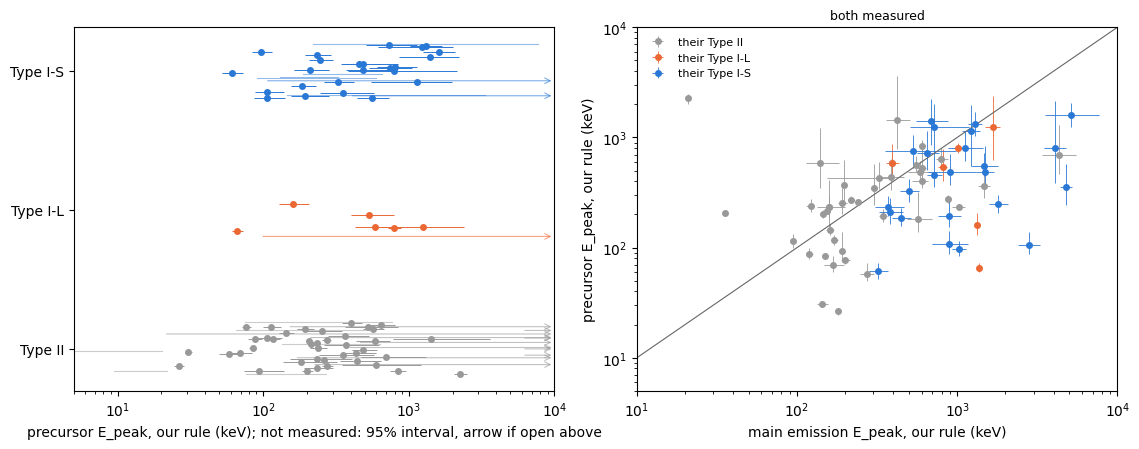

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
rng = np.random.default_rng(2)
rows_y = {"II": 0, "I-L": 1, "I-S": 2}
for kind, y in rows_y.items():
    sel = pe[pe.Type == kind]
    m = sel[sel.measured_PE == True]
    jitter = rng.uniform(-0.2, 0.2, len(m))
    ax.errorbar(m.Ep_PE_ours, y + jitter, xerr=[m.Ep_PE_ours_lo.fillna(0), m.Ep_PE_ours_hi.fillna(0)], fmt="o", ms=4, color=COLOURS[kind], elinewidth=0.7)
    u = sel[sel.measured_PE != True].dropna(subset=["Ep_PE_cpl_limit_lo"])
    jitter = rng.uniform(-0.2, 0.2, len(u))
    for (lo, hi), yy in zip(u[["Ep_PE_cpl_limit_lo", "Ep_PE_cpl_limit_hi"]].values, y + jitter):
        if np.isfinite(hi) and hi <= 1e4:
            ax.plot([lo, hi], [yy, yy], color=COLOURS[kind], lw=0.8, alpha=0.5)
        else:
            ax.annotate("", xy=(1e4, yy), xytext=(min(lo, 6e3), yy), arrowprops=dict(arrowstyle="->", color=COLOURS[kind], lw=0.8, alpha=0.6))
ax.set_xscale("log"); ax.set_xlim(5, 1e4)
ax.set_yticks(list(rows_y.values()), [f"Type {k}" for k in rows_y])
ax.set_xlabel("precursor E_peak, our rule (keV); not measured: 95% interval, arrow if open above")
ax = axes[1]
for kind in ("II", "I-L", "I-S"):
    sel = both[(both.Type == kind)].dropna(subset=["Ep_ME_ours"])
    ax.errorbar(sel.Ep_ME_ours, sel.Ep_PE_ours, xerr=[sel.Ep_ME_ours_lo.fillna(0), sel.Ep_ME_ours_hi.fillna(0)],
                yerr=[sel.Ep_PE_ours_lo.fillna(0), sel.Ep_PE_ours_hi.fillna(0)], fmt="o", ms=4, color=COLOURS[kind], elinewidth=0.6,
                label=f"their Type {kind}")
lim = [10, 1e4]
ax.plot(lim, lim, color="0.4", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(5, 1e4)
ax.set_xlabel("main emission E_peak, our rule (keV)"); ax.set_ylabel("precursor E_peak, our rule (keV)")
ax.set_title("both measured", fontsize=9)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "24_precursor_epeak.png", dpi=140)
plt.show()

96 precursors are fitted; our rule counts 71 E_peak as measured, and keeps the rest as 95% intervals. Measured precursors are
harder in their Type I bursts (geometric mean 398 keV against 240 keV), but the two overlap a lot: the area under the ROC curve is
0.65 (68%: 0.58-0.71). The ratio to the main emission is lower in Type I (median 0.55 against 0.96). Neither comes close to the
separation EPI gives (area about 1). On its own the precursor's E_peak is a weak indicator of their type; notebook 26 tests whether it
adds anything to EPI.

### Tan et al.'s three Type IL candidates

Tan et al. (2025) fitted the precursor and the main emission of GRB 170228A, 200311A and 200914A with a cutoff power law (their values in `shared/tan2025_type_il_fits.csv`). Notebook 18 refitted the same spectra on their windows; here they are beside our fits on the windows of the zhu2026 rule.


In [9]:
tan = pd.read_csv("shared/tan2025_type_il_fits.csv", comment="#")
rows = []
for r in tan.itertuples():
    name, key = r.burst[3:], ("PE" if r.episode == "pre" else "ME")
    if name not in ours.index:
        continue
    o = ours.loc[name]
    start, stop = o[f"{key.lower()}_start"], o[f"{key.lower()}_stop"]
    rows.append({"burst": r.burst, "episode": r.episode, "Tan window": f"{r.t_start:g} to {r.t_stop:g}",
                 "our window": f"{start:.3f} to {stop:.3f}" if pd.notna(start) else "no episode",
                 "Tan E_p": r.Epeak_keV, "Tan E_p range": (f"{(2 + r.alpha) * (r.Ecut_keV - r.Ecut_minus):.0f}-{(2 + r.alpha) * (r.Ecut_keV + r.Ecut_plus):.0f}"
                                                            if pd.notna(r.Ecut_minus) else "not entered"),
                 "Tan alpha": r.alpha, "our E_p (our rule)": o[f"Ep_{key}_ours"], "minus": o[f"Ep_{key}_ours_lo"],
                 "plus": o[f"Ep_{key}_ours_hi"], "model": o[f"model_{key}_ours"], "measured": o.get(f"measured_{key}"),
                 "our E_p (their way)": o[f"Ep_{key}_zhu"],
                 "95% interval if not measured": ("" if pd.notna(o.get(f"measured_{key}")) and bool(o.get(f"measured_{key}")) else
                                                  f"{o.get(f'Ep_{key}_cpl_limit_lo'):.0f}-{o.get(f'Ep_{key}_cpl_limit_hi'):.0f}")})
pd.DataFrame(rows).set_index(["burst", "episode"]).round(1)


Tan window       our window  Tan E_p Tan E_p range  Tan alpha  our E_p (our rule)  minus    plus         model  measured  our E_p (their way) 95% interval if not measured
burst      episode                                                                                                                                                                             
GRB170228A pre      -0.5 to 0.3  -0.448 to 0.256   1102.0      491-2784       -1.0               536.4  133.5   258.0   Comptonized      True                433.9                             
           main       1.4 to 20   1.472 to 9.248    824.2       744-921       -0.6               813.7   49.6    55.4   Comptonized      True                821.7                             
GRB200311A pre      -0.3 to 0.1  -0.096 to 1.936   1263.6      470-2160       -1.5               795.9   79.0    95.1   Comptonized      True                789.4                             
           main       0.3 to 18  2.272 to 17.552   1147.0     1059-1240       -0.7              1012.8   75.9    76.2  BandLowBreak      True               1213.7                             
GRB200914A pre      -0.3 to 0.1  -0.480 to 0.064   1052.1      360-3106       -0.7              1253.2  624.5  1149.4   Comptonized      True               1314.4                             
           main       0.3 to 19  1.296 to 19.168   1134.6     1005-1281       -0.8              1664.7  169.8   185.2   Comptonized      True               1579.9

Our precursor E_peak for Tan et al.'s three candidates lie inside their wide ranges: 536 keV against 1102 (491-2784) for GRB 170228A,
796 against 1264 (470-2160) for 200311A, and 1253 against 1052 (360-3106) for 200914A. Their precursor fits are poorly constrained
(the cut-off energy has errors as large as itself), and the windows differ: 200311A's precursor is 0.4 s in theirs and 2.0 s under the
zhu2026 rule. So closer agreement isn't expected. The main emissions agree for 170228A (814 against 824 keV) and, fitted their way, for
200311A (1214 against 1147). 200914A's is higher than theirs (1665 +/- 180 against 1135 keV), as notebook 18 also found.


## 6. The lags

tau32 is the lag of 25-50 keV behind 50-100 keV, at the finest resolution (4-256 ms) at which at least 90% of Poisson resamples give a real cross-correlation peak and both bands are 5 sigma (`zhu/lags.py`). A real peak is a highest point at least 4 bins from either end of the range of trial lags, with a parabola through the 9 points around it that opens downwards and has its top inside them. The value and its errors are the median and the 16th-84th percentiles of the 1000 resamples that have one. Their table is compared with the version cut at the window, which is probably theirs and gets its own peak test; a lag that fails is not quoted, and its status says why.

In [10]:
for ep in ("PE", "ME", "WE"):
    print(f"tau32,{ep}:", ours.get(f"tau32_{ep}_status", pd.Series(dtype=str)).fillna("no window").value_counts().to_dict())
rows = []
for ep in ("ME", "WE"):
    theirs = table.loc[ours.index, f"tau32_{ep}_ms"]
    mine = ours.get(f"tau32_{ep}_cut_ms", pd.Series(np.nan, index=ours.index))
    err = 0.5 * (ours.get(f"tau32_{ep}_cut_down", np.nan) + ours.get(f"tau32_{ep}_cut_up", np.nan))
    pull = (mine - theirs) / err
    ok = mine.notna()
    rows.append(dict(lag=f"tau32,{ep}", bursts=int(ok.sum()), median_difference_ms=(mine - theirs)[ok].median(), within_1_sigma=np.mean(np.abs(pull[ok]) <= 1), within_3_sigma=np.mean(np.abs(pull[ok]) <= 3),
                     same_sign=np.mean(np.sign(mine[ok]) == np.sign(theirs[ok]))))
pd.DataFrame(rows).set_index("lag").round(2)

tau32,PE: {'unusable:faint': 41, 'measured': 27, 'unusable:too_few_bins': 16, 'no window': 14, 'unusable:no_reliable_peak': 12}
tau32,ME: {'measured': 94, 'unusable:faint': 11, 'unusable:no_reliable_peak': 4, 'unusable:too_few_bins': 1}
tau32,WE: {'measured': 94, 'unusable:faint': 12, 'unusable:no_reliable_peak': 4}


,bursts,median_difference_ms,within_1_sigma,within_3_sigma,same_sign
lag,,,,,
"tau32,ME",88,-25.08,0.45,0.83,0.86
"tau32,WE",92,-17.73,0.46,0.79,0.87


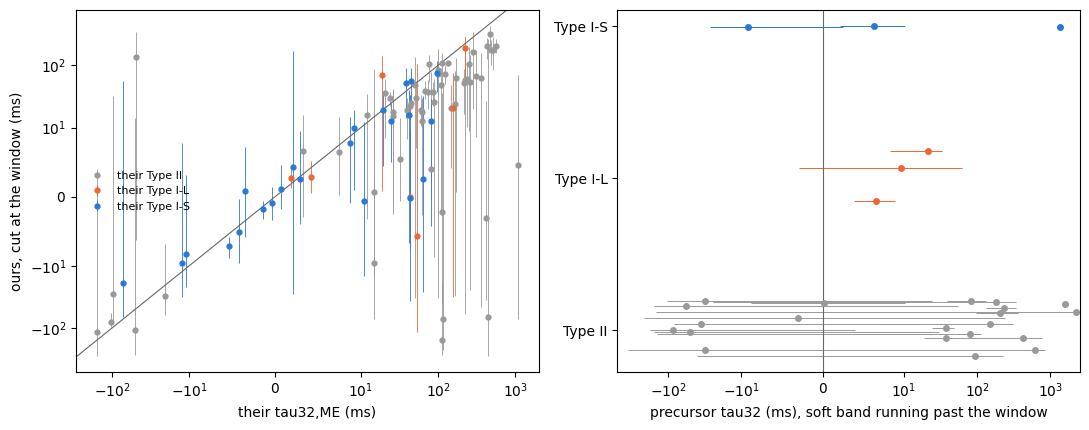

precursor lags measured: 27 {'II': 21, 'I-S': 3, 'I-L': 3}
      count   50%   min     max
Type                           
I-L     3.0   9.7   6.6    21.3
I-S     3.0   6.3  -9.2  1347.0
II     21.0  81.0 -85.1  2239.5


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
for kind in ("II", "I-L", "I-S"):
    sel = ours[(ours.Type == kind)] if "Type" in ours else ours
    ax.errorbar(table.loc[sel.index, "tau32_ME_ms"], sel.get("tau32_ME_cut_ms"), yerr=[sel.get("tau32_ME_cut_down"), sel.get("tau32_ME_cut_up")], fmt="o", ms=3.5, color=COLOURS[kind], elinewidth=0.6, label=f"their Type {kind}")
ax.axline((0, 0), slope=1, color="0.4", lw=0.8)
ax.set_xscale("symlog", linthresh=10); ax.set_yscale("symlog", linthresh=10)
ax.set_xlabel("their tau32,ME (ms)"); ax.set_ylabel("ours, cut at the window (ms)")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
rng = np.random.default_rng(4)
for kind, y in {"II": 0, "I-L": 1, "I-S": 2}.items():
    sel = ours[(ours.Type == kind) & ours.get("tau32_PE_ms", pd.Series(dtype=float)).notna()]
    ax.errorbar(sel.tau32_PE_ms, y + rng.uniform(-0.2, 0.2, len(sel)), xerr=[sel.tau32_PE_down, sel.tau32_PE_up], fmt="o", ms=4, color=COLOURS[kind], elinewidth=0.7)
ax.axvline(0, color="0.4", lw=0.8)
ax.set_xscale("symlog", linthresh=10)
ax.set_yticks([0, 1, 2], ["Type II", "Type I-L", "Type I-S"])
ax.set_xlabel("precursor tau32 (ms), soft band running past the window")
fig.tight_layout()
fig.savefig(FIGURES / "24_lags.png", dpi=140)
plt.show()
pe_lags = ours[ours.get("tau32_PE_ms", pd.Series(dtype=float)).notna()]
print("precursor lags measured:", len(pe_lags), pe_lags.Type.value_counts().to_dict())
print(pe_lags.groupby("Type").tau32_PE_ms.describe()[["count", "50%", "min", "max"]].round(1))

tau32 of the main emission is measured for 94 bursts and of the precursor for only 27: faint or short precursors don't give a
reliable cross-correlation peak. Against their values, ours are within 1 sigma for about half and within 3 sigma for 83%, with the same
sign for 86%; ours are shorter by a median 25 ms. Precursor lags are short in their Type I bursts (medians 10 and 6 ms) and longer in
Type II (81 ms), but with three Type I-L and three I-S precursors that is a hint, not a result.

## 7. What this says

The spectral half of their table is reproduced: fitted their way, E_p,ME is within 0.1 dex of theirs for two thirds of the bursts, and
where we differ the GBM catalogue is usually closer to ours. How E_p,ME is fitted adds a systematic of about 0.08 dex. Precursors are harder in
their Type I bursts but overlap strongly with Type II; whether that adds anything to EPI is notebook 26's question.